# Modelagem preditiva da produtividade da safra de soja com uso de aprendizado de máquina e dados agrometeorológicos — Modelagem (teste de outros algoritmos)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** teste complementar, motivado pelos comentários do orientador ("Existem outros algoritmos que podem ser considerados? E variações do Gradient Boosting?" e "Pesquisaram outras categorias de algoritmos?"). Compara o modelo final FL com um modelo misto (efeitos por mesorregião), Lasso, Elastic Net, SVR, Gradient Boosting com ajuste de hiperparâmetros e XGBoost com ajuste de hiperparâmetros, usando a mesma base (NASA POWER), o mesmo patamar e as mesmas duas validações da Etapa 5. Os hiperparâmetros são escolhidos só com safras do treino. Este notebook não altera o modelo final nem os resultados do artigo.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-11-06 |                 | Criação do notebook — lista de modelos e regra de decisão definidas antes da execução |
| 2026-11-06 |                 | Notebook executado no `.venv` (Python 3.13); conclusões (seção 6) registradas com a saída desta execução |
| 2026-11-06 |                 | Decisão atualizada: o teste passa a ser citado na seção 4.3 do artigo |

## 1. Imports e configuração

Mesmas convenções da Etapa 5. O clima por célula e safra é lido de
`clima_nasa_power_celula_safra.csv`, salvo pela Etapa 5, sem recálculo.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from statsmodels.regression.mixed_linear_model import MixedLM
from xgboost import XGBRegressor

RAW = "../dataset/raw"
PROCESSED = "../dataset/processed"

ANO_CORTE = 2020          # corte temporal: treino até 2020, teste 2021-2025
DEFASAGEM_PUBLICACAO = 2  # em março de 2026, a última PAM/IBGE publicada é a de 2024 (dois anos antes)
PRIMEIRA_SAFRA = 2006     # primeira safra com 5 safras publicadas para o patamar
SEED = 42
PERCENTIL_LIMIAR = 0.2    # limiares de seca extrema: 20% mais secos do treino
DOBRAS_INTERNAS = 4       # validação interna do ajuste, separando safras inteiras
REPETICOES_BOOTSTRAP = 5000

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Ambiente pronto.")

Ambiente pronto.


## 2. Base de modelagem

Reproduz a base do NASA POWER da Etapa 5: rendimento do IBGE, clima da célula que contém o
município e patamar calculado só com as safras publicadas na data da previsão (Y−2). O
rótulo do treino é o **desvio**: rendimento observado menos patamar. A previsão final é
patamar + desvio previsto.

In [2]:
ALVO = "rendimento_kg_ha"
ONI = "oni_media_safra"
CLIMA = ["chuva_out_nov", "chuva_dez_fev", "chuva_mar", "seca_max_dez_fev",
         "dias_calor_dez_fev", "tmax_dez_fev", "urmin_dez_fev"]
VAR_HIDRICO = ["deficit_dez_fev", "balanco_dez_fev", "eto_dez_fev"]
CHAVE = ["codigo_ibge_municipio", "ano_safra"]


def chave_celula(lat, lon):
    return lat.map("{:.3f}".format) + "_" + lon.map("{:.4f}".format)


painel = pd.read_csv(f"{PROCESSED}/painel_municipio_safra.csv")
mapa = pd.read_csv(f"{RAW}/nasa_power_celulas_municipios_rs.csv")
mapa["celula"] = chave_celula(mapa["lat_celula"], mapa["lon_celula"])
clima_power = pd.read_csv(f"{PROCESSED}/clima_nasa_power_celula_safra.csv")
clima_power["celula"] = chave_celula(clima_power["lat_celula"], clima_power["lon_celula"])
regioes = pd.read_csv(f"{RAW}/ibge_municipios_rs_regioes.csv",
                      usecols=["codigo_ibge_municipio", "mesorregiao"])
regioes["mesorregiao"] = regioes["mesorregiao"].str.replace(" Rio-grandense", "")

com_rendimento = painel.dropna(subset=[ALVO])
rend = com_rendimento.pivot_table(index="ano_safra", columns="codigo_ibge_municipio", values=ALVO)
estado = rend.mean(axis=1)
partes = []
for ano in range(PRIMEIRA_SAFRA, int(rend.index.max()) + 1):
    ultima = ano - DEFASAGEM_PUBLICACAO   # última safra publicada em março de `ano`
    j5, todos = rend.loc[ultima - 4:ultima], rend.loc[:ultima]
    partes.append(pd.DataFrame({
        "ano_safra": ano,
        "patamar_mm5": j5.mean().where(j5.count() >= 3, estado.loc[ultima - 4:ultima].mean()),
        "base_media_hist": todos.mean().where(todos.count() >= 3, estado.loc[:ultima].mean()),
    }))
patamares = pd.concat(partes).rename_axis("codigo_ibge_municipio").reset_index()

OBRIGATORIAS = [ALVO, ONI, "patamar_mm5", "base_media_hist"] + CLIMA + VAR_HIDRICO
base = (painel.merge(mapa[["codigo_ibge_municipio", "celula"]], on="codigo_ibge_municipio")
        .merge(clima_power, on=["celula", "ano_safra"], how="left")
        .merge(patamares, on=CHAVE, how="left")
        .dropna(subset=OBRIGATORIAS))
base = base[base["ano_safra"] >= PRIMEIRA_SAFRA].merge(regioes, on="codigo_ibge_municipio", how="left")
base["desvio"] = base[ALVO] - base["patamar_mm5"]
base = base.reset_index(drop=True)

print(f"{len(base)} linhas | {base['codigo_ibge_municipio'].nunique()} municípios | "
      f"{base['ano_safra'].nunique()} safras | {base['mesorregiao'].nunique()} mesorregiões | "
      f"sem região: {base['mesorregiao'].isna().sum()}")
print(f"Treino do corte: {(base['ano_safra'] <= ANO_CORTE).sum()} | teste: {(base['ano_safra'] > ANO_CORTE).sum()}")

8261 linhas | 449 municípios | 20 safras | 7 mesorregiões | sem região: 0
Treino do corte: 6107 | teste: 2154


## 3. Modelos e regra de decisão

A lista foi definida **antes** de rodar, para limitar a seleção otimista: quanto mais modelos
são comparados nas mesmas safras, maior a chance de um deles vencer por acaso.

| Modelo | Categoria | Variáveis | Ajuste, só com o treino |
|---|---|---|---|
| **FL** | Regressão linear | as do modelo final | nenhum (referência) |
| **GB original** | Árvores (*boosting*) | as da Etapa 5 | nenhum (referência) |
| **Modelo misto** | Linear com efeitos por região | as do FL, com intercepto e efeitos de chuva e seca por mesorregião | variâncias por REML |
| **Lasso** | Linear com penalização | candidatas amplas | força da penalização |
| **Elastic Net** | Linear com penalização | candidatas amplas | força e tipo da penalização |
| **SVR** | Vetores de suporte (kernel RBF) | as do GB | `C` e `gamma` |
| **GB ajustado** | Árvores (*boosting*) | as do GB | taxa, iterações e profundidade |
| **XGBoost ajustado** | Árvores (*boosting*) | as do GB | taxa, árvores e profundidade |

A validação interna do ajuste separa **safras inteiras**, porque os municípios de uma mesma
safra compartilham o mesmo ano climático. Na validação "deixa uma safra de fora", a safra
testada nunca entra no ajuste. Os limiares de seca usam o treino de cada rodada externa.

**Regra de decisão.** Um modelo só é candidato a substituir o FL se tiver:

1. RMSE menor que o do FL nas **duas** validações; e
2. intervalo de 95% da diferença de RMSE para o FL inteiro abaixo de zero na validação
   "deixa uma safra de fora" (*bootstrap* por safra).

O corte temporal tem só 5 safras, e por isso o seu intervalo é apenas informativo. Mesmo um
candidato só deve substituir o FL depois de confirmado em safra não usada na escolha.

In [3]:
FEAT_F = ["chuva_out_nov_100", "chuva_dez_fev_c100", "chuva_dez_fev_c100_2", "chuva_mar_100",
          "dias_calor_dez_fev", "urmin_dez_fev"]
FEAT_H2 = FEAT_F + ["deficit_100", "limiar_urmin", "limiar_deficit_100"]
FEAT_FL = FEAT_F + ["limiar_deficit_100"]
FEAT_GB = CLIMA + [ONI] + VAR_HIDRICO
FEAT_AMPLAS = FEAT_H2 + ["seca_max_dez_fev", "tmax_dez_fev", ONI, "balanco_dez_fev", "eto_dez_fev"]
FEAT_REGIAO = ["chuva_dez_fev_c100", "limiar_deficit_100"]   # efeitos que variam por mesorregião

BASE_HIST = "Linha de base: média histórica"
FL = "FL (final)"
MODELOS = [FL, "Modelo misto", "Lasso", "Elastic Net", "SVR", "GB original", "GB ajustado",
           "XGBoost ajustado", BASE_HIST]
ALPHAS = np.logspace(0, 3, 30)

GRADE_SVR = {"regressor__svr__C": [0.3, 1, 3], "regressor__svr__gamma": [0.01, 0.03, 0.1]}
GRADE_GB = {"learning_rate": [0.03, 0.1], "max_iter": [100, 300], "max_depth": [2, 4, None]}
GRADE_XGB = {"learning_rate": [0.03, 0.1], "n_estimators": [100, 300], "max_depth": [2, 4]}


def derivar(d, ref):
    d = d.copy()
    d["chuva_out_nov_100"] = d["chuva_out_nov"] / 100
    d["chuva_dez_fev_c100"] = (d["chuva_dez_fev"] - ref["chuva"]) / 100
    d["chuva_dez_fev_c100_2"] = d["chuva_dez_fev_c100"] ** 2
    d["chuva_mar_100"] = d["chuva_mar"] / 100
    d["deficit_100"] = d["deficit_dez_fev"] / 100
    d["limiar_urmin"] = (ref["urmin"] - d["urmin_dez_fev"]).clip(lower=0)
    d["limiar_deficit_100"] = (d["deficit_dez_fev"] - ref["deficit"]).clip(lower=0) / 100
    return d


def referencias(tr):
    return {"chuva": tr["chuva_dez_fev"].mean(),
            "urmin": tr["urmin_dez_fev"].quantile(PERCENTIL_LIMIAR),
            "deficit": tr["deficit_dez_fev"].quantile(1 - PERCENTIL_LIMIAR)}


def dobras_por_safra(tr):
    # Nenhuma safra aparece no treino e na validação da mesma dobra interna
    return list(GroupKFold(n_splits=DOBRAS_INTERNAS).split(tr, groups=tr["ano_safra"]))


def ajustar(estimador, grade, tr, feats):
    busca = GridSearchCV(estimador, grade, cv=dobras_por_safra(tr), n_jobs=-1,
                         scoring="neg_root_mean_squared_error")
    return busca.fit(tr[feats], tr["desvio"])


def prever_misto(tr, te):
    X = sm.add_constant(tr[FEAT_FL], has_constant="add")
    Z = sm.add_constant(tr[FEAT_REGIAO], has_constant="add")
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        ajuste = MixedLM(tr["desvio"], X, groups=tr["mesorregiao"], exog_re=Z).fit(reml=True, method="lbfgs")
    X_te = sm.add_constant(te[FEAT_FL], has_constant="add")
    Z_te = sm.add_constant(te[FEAT_REGIAO], has_constant="add")
    fixo = X_te.to_numpy() @ ajuste.fe_params.to_numpy()
    efeitos = pd.DataFrame(ajuste.random_effects).T[Z.columns]
    regional = (Z_te.to_numpy() * efeitos.reindex(te["mesorregiao"]).fillna(0).to_numpy()).sum(axis=1)
    return fixo + regional, ajuste.converged, len(avisos)


def gb_original():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, min_samples_leaf=20,
                                         early_stopping=True, validation_fraction=0.1,
                                         random_state=SEED)


def svr_escalado():
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), SVR(epsilon=0.1)),
                                      transformer=StandardScaler())


escolhas = []


def prever_todos(tr, te, rodada):
    ref = referencias(tr)
    tr, te = derivar(tr, ref), derivar(te, ref)
    pat = te["patamar_mm5"].to_numpy()
    saida = {BASE_HIST: te["base_media_hist"].to_numpy()}
    registro = {"rodada": rodada}

    saida[FL] = pat + LinearRegression().fit(tr[FEAT_FL], tr["desvio"]).predict(te[FEAT_FL])
    saida["GB original"] = pat + gb_original().fit(tr[FEAT_GB], tr["desvio"]).predict(te[FEAT_GB])

    misto, convergiu, avisos = prever_misto(tr, te)
    saida["Modelo misto"] = pat + misto
    registro["misto convergiu"], registro["misto avisos"] = convergiu, avisos

    dobras = dobras_por_safra(tr)
    lasso = make_pipeline(StandardScaler(), LassoCV(alphas=ALPHAS, cv=dobras, max_iter=20000))
    lasso.fit(tr[FEAT_AMPLAS], tr["desvio"])
    saida["Lasso"] = pat + lasso.predict(te[FEAT_AMPLAS])
    registro["Lasso alpha"] = lasso[-1].alpha_
    registro["Lasso variáveis"] = int((lasso[-1].coef_ != 0).sum())

    enet = make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], alphas=ALPHAS,
                                                        cv=dobras, max_iter=20000))
    enet.fit(tr[FEAT_AMPLAS], tr["desvio"])
    saida["Elastic Net"] = pat + enet.predict(te[FEAT_AMPLAS])
    registro["Elastic Net alpha"], registro["Elastic Net l1"] = enet[-1].alpha_, enet[-1].l1_ratio_

    svr = ajustar(svr_escalado(), GRADE_SVR, tr, FEAT_GB)
    saida["SVR"] = pat + svr.predict(te[FEAT_GB])
    registro["SVR"] = str({k.split("__")[-1]: v for k, v in svr.best_params_.items()})

    hgb = ajustar(HistGradientBoostingRegressor(min_samples_leaf=20, early_stopping=False, random_state=SEED),
                  GRADE_GB, tr, FEAT_GB)
    saida["GB ajustado"] = pat + hgb.predict(te[FEAT_GB])
    registro["GB ajustado"] = str(hgb.best_params_)

    xgb = ajustar(XGBRegressor(min_child_weight=20, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                               n_jobs=1, random_state=SEED), GRADE_XGB, tr, FEAT_GB)
    saida["XGBoost ajustado"] = pat + xgb.predict(te[FEAT_GB])
    registro["XGBoost ajustado"] = str(xgb.best_params_)

    escolhas.append(registro)
    return saida


def validar(base):
    ident = base[CHAVE + [ALVO, "patamar_mm5", "mesorregiao"]]
    tr, te = base[base["ano_safra"] <= ANO_CORTE], base[base["ano_safra"] > ANO_CORTE]
    corte = ident.loc[te.index].assign(**prever_todos(tr, te, "corte"))
    partes = []
    for ano in [a for a in sorted(base["ano_safra"].unique()) if a >= 2008]:
        tr, te = base[base["ano_safra"] != ano], base[base["ano_safra"] == ano]
        partes.append(ident.loc[te.index].assign(**prever_todos(tr, te, int(ano))))
    return corte, pd.concat(partes)


def metricas(y, pred):
    return {"RMSE": mean_squared_error(y, pred) ** 0.5, "MAE": mean_absolute_error(y, pred),
            "R²": r2_score(y, pred), "Viés": np.mean(pred - y),
            "Acurácia (%)": 100 * (1 - np.abs(pred - y).sum() / y.sum())}


print("Modelos:", ", ".join(MODELOS))

Modelos: FL (final), Modelo misto, Lasso, Elastic Net, SVR, GB original, GB ajustado, XGBoost ajustado, Linha de base: média histórica


## 4. Execução das duas validações

São 19 rodadas: o corte temporal e 18 safras na validação "deixa uma safra de fora". Em cada
uma, todos os modelos são reajustados com o treino daquela rodada.

In [4]:
inicio = time.time()
corte, loyo = validar(base)
print(f"Concluído em {(time.time() - inicio) / 60:.1f} min")
print(f"Corte: {len(corte)} linhas | deixa uma safra de fora: {len(loyo)} linhas")

Concluído em 16.7 min
Corte: 2154 linhas | deixa uma safra de fora: 7472 linhas


### Conferência com a Etapa 5

O FL e o GB original precisam reproduzir os números do artigo; se não reproduzirem, a
comparação abaixo não vale.

In [5]:
ESPERADO = {FL: (772, 626), "GB original": (958, 698), BASE_HIST: (868, 905)}
conferencia = pd.DataFrame({m: {"RMSE corte": mean_squared_error(corte[ALVO], corte[m]) ** 0.5,
                                "esperado corte": e[0],
                                "RMSE deixa uma de fora": mean_squared_error(loyo[ALVO], loyo[m]) ** 0.5,
                                "esperado deixa uma de fora": e[1]}
                            for m, e in ESPERADO.items()}).T
conferencia.round(1)

,RMSE corte,esperado corte,RMSE deixa uma de fora,esperado deixa uma de fora
FL (final),771.90,772.00,626.40,626.00
GB original,957.80,958.00,697.60,698.00
Linha de base: média histórica,868.30,868.00,904.60,905.00


## 5. Resultados

Ordenados pela média do RMSE nas duas validações, o critério de escolha do modelo final
desde a Etapa 3 (RMSE, MAE e viés em kg/ha).

In [6]:
linhas = {}
for m in MODELOS:
    c, l = metricas(corte[ALVO], corte[m]), metricas(loyo[ALVO], loyo[m])
    linhas[m] = {**{("Corte 2021–2025", k): v for k, v in c.items()},
                 **{("Deixa uma safra de fora", k): v for k, v in l.items()},
                 ("Média", "RMSE"): (c["RMSE"] + l["RMSE"]) / 2}
resultados = pd.DataFrame(linhas).T.sort_values(("Média", "RMSE"))
resultados.columns = pd.MultiIndex.from_tuples(resultados.columns)
resultados.round(2)

Corte 2021–2025                       \
                                          RMSE    MAE    R²    Viés   
Modelo misto                            676.93 534.35  0.44  252.79   
Lasso                                   800.87 628.91  0.22  309.11   
FL (final)                              771.86 604.13  0.28  298.10   
Elastic Net                             814.10 637.31  0.20  335.09   
SVR                                     939.25 710.94 -0.07  473.65   
XGBoost ajustado                        973.52 758.80 -0.15  566.08   
GB ajustado                             969.58 739.64 -0.14  519.23   
GB original                             957.82 735.24 -0.11  495.80   
Linha de base: média histórica          868.29 737.29  0.09 -105.62   

                                            Deixa uma safra de fora         \
                               Acurácia (%)                    RMSE    MAE   
Modelo misto                          78.15                  585.67 448.00   
Lasso                                 74.29                  595.39 450.01   
FL (final)                            75.30                  626.36 476.31   
Elastic Net                           73.94                  611.62 461.48   
SVR                                   70.93                  639.96 485.97   
XGBoost ajustado                      68.98                  636.41 489.42   
GB ajustado                           69.76                  651.10 495.13   
GB original                           69.94                  697.55 531.58   
Linha de base: média histórica        69.86                  904.63 785.34   

                                                           Média  
                                  R²    Viés Acurácia (%)   RMSE  
Modelo misto                    0.48   40.45        82.58 631.30  
Lasso                           0.46   57.61        82.51 698.13  
FL (final)                      0.40   46.78        81.48 699.11  
Elastic Net                     0.43   44.39        82.06 712.86  
SVR                             0.38   50.44        81.11 789.61  
XGBoost ajustado                0.38   55.72        80.97 804.97  
GB ajustado                     0.36   63.47        80.75 810.34  
GB original                     0.26   71.60        79.33 827.69  
Linha de base: média histórica -0.24 -482.27        69.47 886.46

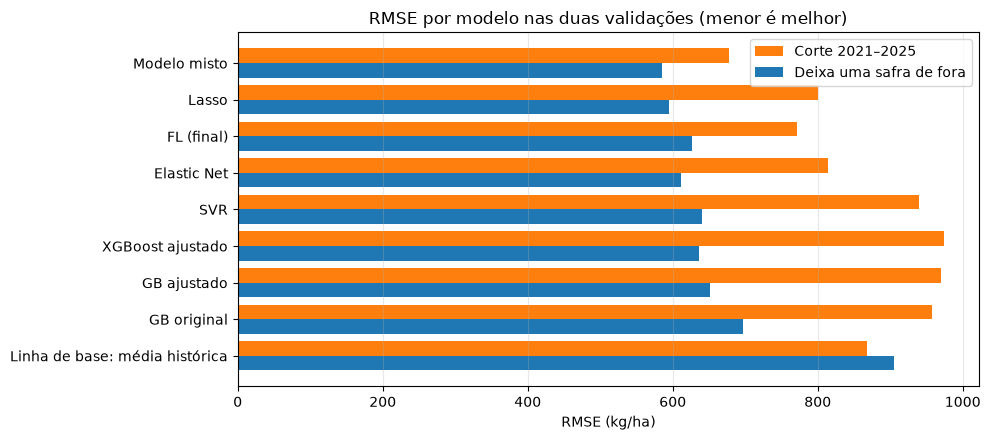

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ordem = resultados.index
y = np.arange(len(ordem))
ax.barh(y - 0.2, resultados[("Corte 2021–2025", "RMSE")], height=0.4, color="tab:orange", label="Corte 2021–2025")
ax.barh(y + 0.2, resultados[("Deixa uma safra de fora", "RMSE")], height=0.4, color="tab:blue", label="Deixa uma safra de fora")
ax.set_yticks(y, ordem)
ax.invert_yaxis()
ax.set_xlabel("RMSE (kg/ha)")
ax.set_title("RMSE por modelo nas duas validações (menor é melhor)")
ax.grid(axis="x", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### A diferença para o FL é maior que o acaso?

Diferença de RMSE para o FL (negativa = melhor que o FL), com intervalo de 95% por *bootstrap*
que sorteia **safras inteiras**, e número de safras em que o modelo erra menos que o FL. A
última coluna aplica a regra de decisão da seção 3.

In [8]:
def dif_bootstrap(prev, modelo):
    # Soma dos erros quadráticos por safra, para sortear safras inteiras
    grupos = prev.assign(a=(prev[modelo] - prev[ALVO]) ** 2, b=(prev[FL] - prev[ALVO]) ** 2).groupby("ano_safra")
    s = grupos[["a", "b"]].sum()
    n = grupos.size().to_numpy()
    a, b = s["a"].to_numpy(), s["b"].to_numpy()
    rng = np.random.default_rng(SEED)
    idx = rng.integers(0, len(s), size=(REPETICOES_BOOTSTRAP, len(s)))
    dif = np.sqrt(a[idx].sum(axis=1) / n[idx].sum(axis=1)) - np.sqrt(b[idx].sum(axis=1) / n[idx].sum(axis=1))
    observado = np.sqrt(a.sum() / n.sum()) - np.sqrt(b.sum() / n.sum())
    return observado, *np.percentile(dif, [2.5, 97.5]), int((a / n < b / n).sum()), len(s)


linhas = {}
for m in [x for x in MODELOS if x != FL]:
    dc, ic1, ic2, vc, nc = dif_bootstrap(corte, m)
    dl, il1, il2, vl, nl = dif_bootstrap(loyo, m)
    linhas[m] = {"corte: dif. RMSE": dc, "corte: IC 2,5%": ic1, "corte: IC 97,5%": ic2,
                 "corte: safras melhor": f"{vc}/{nc}",
                 "deixa uma: dif. RMSE": dl, "deixa uma: IC 2,5%": il1, "deixa uma: IC 97,5%": il2,
                 "deixa uma: safras melhor": f"{vl}/{nl}",
                 "candidato a substituir o FL": bool(dc < 0 and dl < 0 and il2 < 0)}
comparacao = pd.DataFrame(linhas).T.sort_values("deixa uma: dif. RMSE")
comparacao

,corte: dif. RMSE,"corte: IC 2,5%","corte: IC 97,5%",corte: safras melhor,deixa uma: dif. RMSE,"deixa uma: IC 2,5%","deixa uma: IC 97,5%",deixa uma: safras melhor,candidato a substituir o FL
Modelo misto,-94.93,-186.93,-1.24,4/5,-40.69,-91.61,-0.57,11/18,True
Lasso,29.01,2.54,48.68,1/5,-30.97,-58.16,-5.36,11/18,False
Elastic Net,42.24,2.30,68.62,2/5,-14.75,-36.78,4.15,10/18,False
XGBoost ajustado,201.66,57.03,296.23,0/5,10.05,-15.83,35.11,6/18,False
SVR,167.39,6.01,315.43,2/5,13.60,-40.45,68.19,8/18,False
GB ajustado,197.72,19.15,306.56,1/5,24.74,-16.98,65.38,7/18,False
GB original,185.96,23.55,299.64,0/5,71.19,9.65,130.94,6/18,False
Linha de base: média histórica,96.43,-94.12,353.67,2/5,278.26,129.95,429.21,4/18,False


### Por mesorregião

RMSE por região na validação "deixa uma safra de fora". É aqui que o modelo misto deveria
ajudar, se a resposta ao clima realmente mudar entre as regiões.

In [9]:
por_regiao = pd.DataFrame({m: loyo.groupby("mesorregiao")[[ALVO, m]].apply(
    lambda g: mean_squared_error(g[ALVO], g[m]) ** 0.5) for m in resultados.index if m != BASE_HIST})
por_regiao.insert(0, "linhas", loyo.groupby("mesorregiao").size())
por_regiao.sort_values("linhas", ascending=False).round(0)

,linhas,Modelo misto,Lasso,FL (final),Elastic Net,SVR,XGBoost ajustado,GB ajustado,GB original
mesorregiao,,,,,,,,,
Noroeste,3888,555.00,567.00,596.00,592.00,655.00,631.00,652.00,714.00
Centro Oriental,891,593.00,571.00,603.00,588.00,585.00,592.00,605.00,667.00
Metropolitana de Porto Alegre,692,644.00,652.00,673.00,645.00,641.00,647.00,642.00,631.00
Nordeste,687,556.00,598.00,641.00,635.00,629.00,672.00,688.00,742.00
Centro Ocidental,558,591.00,536.00,569.00,551.00,570.00,597.00,621.00,669.00
Sudeste,427,719.00,742.00,778.00,717.00,696.00,720.00,709.00,705.00
Sudoeste,329,648.00,727.00,763.00,722.00,655.00,666.00,670.00,651.00


### Hiperparâmetros escolhidos

O que o ajuste escolheu em cada rodada e se o modelo misto convergiu. Escolhas muito instáveis
entre as rodadas indicam que há pouca informação para definir os hiperparâmetros.

In [10]:
escolhidos = pd.DataFrame(escolhas).set_index("rodada")
print(f"Modelo misto: convergiu em {int(escolhidos['misto convergiu'].sum())} de {len(escolhidos)} rodadas; "
      f"rodadas com aviso: {int((escolhidos['misto avisos'] > 0).sum())}")
frequencia = pd.concat({m: escolhidos[m].value_counts() for m in ["SVR", "GB ajustado", "XGBoost ajustado"]})
frequencia.name = "rodadas"
display(frequencia.to_frame())
escolhidos[["Lasso alpha", "Lasso variáveis", "Elastic Net alpha", "Elastic Net l1"]].round(2)

Modelo misto: convergiu em 19 de 19 rodadas; rodadas com aviso: 2


rodadas
SVR              {'C': 0.3, 'gamma': 0.01}                                16
                 {'C': 0.3, 'gamma': 0.03}                                 3
GB ajustado      {'learning_rate': 0.03, 'max_depth': 2, 'max_it...       14
                 {'learning_rate': 0.03, 'max_depth': 2, 'max_it...        3
                 {'learning_rate': 0.03, 'max_depth': 4, 'max_it...        1
                 {'learning_rate': 0.1, 'max_depth': 2, 'max_ite...        1
XGBoost ajustado {'learning_rate': 0.03, 'max_depth': 2, 'n_esti...       16
                 {'learning_rate': 0.03, 'max_depth': 2, 'n_esti...        3

,Lasso alpha,Lasso variáveis,Elastic Net alpha,Elastic Net l1
rodada,,,,
corte,3.29,12,1.00,0.80
2008,6.72,10,1.00,0.80
2009,2.59,10,1.00,0.80
2010,8.53,9,1.00,0.80
2011,4.18,11,1.00,0.80
2012,1.00,12,1.00,0.80
2013,5.30,10,1.00,0.80
2014,2.59,12,1.00,0.80
2015,4.18,10,1.00,0.80


## 6. Conclusões

**Conferência.** FL, GB original e média histórica reproduzem os números da Etapa 5 (FL: RMSE 772 e 626 kg/ha), então a comparação é válida.

**Resultados, em RMSE (kg/ha), corte 2021–2025 / deixa uma safra de fora:**

- **Modelo misto: 677 / 586.** Único que passou na regra de decisão, com diferença de −95 e −41 para o FL. Os intervalos de 95% ficam abaixo de zero por muito pouco (até −1 e até −0,6), e ele vence o FL em 4 de 5 e em 11 de 18 safras. O ganho é maior no Sudoeste (763 → 648) e no Nordeste (641 → 556), mas há piora no Centro Ocidental (569 → 591). O viés no corte temporal continua alto (+253 kg/ha).
- **FL: 772 / 626.** Referência.
- **Lasso e Elastic Net: 801 e 814 / 595 e 612.** Melhores que o FL só na validação "deixa uma safra de fora" e piores no corte temporal.
- **SVR: 939 / 640.** Pior que o FL nas duas validações.
- **GB original, GB ajustado e XGBoost ajustado: 958, 970 e 974 / 698, 651 e 636.** O ajuste reduziu o erro em "deixa uma safra de fora", mas não no corte temporal. Nessas safras de seca, os três ficam acima do FL, com intervalo acima de zero.

**O que isso significa para as perguntas do orientador:**

1. **Outras categorias e variações do Gradient Boosting.** Foram testadas, e nenhuma categoria mais complexa superou o FL nas duas validações, nem com ajuste de hiperparâmetros. A conclusão de que os modelos *ensemble* não superaram a regressão linear se mantém.
2. **Onde pode haver ganho.** O melhor resultado veio de um modelo linear com efeitos por região, o que é coerente com a conclusão de que a representação do problema pesa mais que a complexidade do algoritmo.

**Limitações:**

- **Seleção:** sete modelos novos foram comparados nas mesmas safras, sem correção para comparações múltiplas. Um intervalo que quase toca o zero é um indício, não uma confirmação.
- **Poucas safras:** o corte temporal tem 5 safras, e os intervalos com tão poucas safras são imprecisos. O modelo misto também estima as variâncias com só 7 mesorregiões, e 2 das 19 rodadas tiveram aviso numérico, embora todas tenham convergido.
- **Limites das grades:** as escolhas ficaram quase sempre na ponta mais simples das grades (SVR com `C` = 0,3; árvores com taxa de 0,03 e profundidade 2; Elastic Net com `alpha` = 1). Grades mais amplas poderiam mudar um pouco os números de SVR, GB, XGBoost e Elastic Net.
- **Teste fora da amostra:** este notebook não avalia a safra 2026 nem a 2027.

**Decisão.** O FL continua como modelo final. O artigo cita este teste na seção 4.3 (Tabela 8), sem alterar o modelo final nem seus resultados. O modelo misto é candidato a ser confirmado em safra não usada na escolha, como a de 2027 prevista no TCC 2.